# Simulación MEIGA del montaje con la fuente ²⁴¹Am-Be

Entrada lateral (haz 35 %, halo 45 %, fondo 20 %), 1 000 000 de neutrones por medio, PMT de Sidelnik, sin S(α,β).
Calibración p.e./ADC con 2000 muones verticales y comparación con las tomas del prototipo.

Este cuaderno ejecuta los scripts de `scripts/` y muestra sus resultados. El informe está en `informe/Informe-montaje-MEIGA.pdf`.

| Medio | Estado |
|---|---|
| Agua pura | procesado |
| Agua + 2.5 % NaCl | procesado |
| Agua + 10 % NaCl | procesado (22-oct-2026) |

In [1]:
import json, os, subprocess, sys
import numpy as np, pandas as pd
from IPython.display import Image, display
BASE = os.path.abspath(".")
RES, FIG, SCR = (os.path.join(BASE, d) for d in ("resultados", "figuras", "scripts"))
ADATA = "ADATA HD330"
def correr(script, *args):
    r = subprocess.run([sys.executable, os.path.join(SCR, script), *args], capture_output=True, text=True)
    print(r.stdout[-3000:], r.stderr[-2000:])

## 1. Procesamiento de las corridas (opcional, necesita el ADATA)

Lee las 4 partes de cada corrida y deja `resultados/eventos_<medio>.npz`. Los `.npz` de agua pura y 2.5 % ya están hechos;
solo hace falta ejecutar esta celda para una corrida nueva (10 % NaCl).

In [2]:
PROCESAR = False          # True para procesar una corrida nueva
MEDIO = "nacl10"          # pura | nacl25 | nacl10
CARPETA = os.path.join(ADATA, "Corrida-AmBe-montaje-nacl-10-resultados")   # carpeta que contiene 1000000N-...
if PROCESAR:
    d = [os.path.join(CARPETA, x) for x in os.listdir(CARPETA) if x.startswith("1000000N")][0]
    correr("procesar_montaje.py", d, MEDIO)
for m in ("pura", "nacl25", "nacl10"):
    f = os.path.join(RES, f"verificacion_{m}.json")
    if os.path.exists(f):
        v = json.load(open(f)); print(m, "eventos:", v["eventos_total"], "| máx. dif. energía:", max(p["max_dif_rel_energia"] for p in v["partes"].values()))

pura eventos: 1000000 | máx. dif. energía: 0.0006093236520606262
nacl25 eventos: 1000000 | máx. dif. energía: 0.0006093236520606262
nacl10 eventos: 1000000 | máx. dif. energía: 0.0006093236520606262


## 2. Respuesta por componente y modelo de 5 min (1 Ci)

In [3]:
correr("analizar_montaje.py")
R = json.load(open(os.path.join(RES, "resumen_montaje.json")))
filas = []
for m, x in R.items():
    for c in ("haz", "halo", "fondo", "total"):
        y = x[c]; filas.append({"medio": m, "componente": c, "eps(Q>=1) %": 100*y["eps_Q1"], "eta_cap %": 100*y["eta_cap_medio"],
                                "<Q> p.e.": y["Q_media_senal"], "eps(Q>=12) %": 100*y["eps_Q12"], "t_cap mediana us": y["t_cap_mediana_us"],
                                "35Cl %": y["nucleo_pct"].get("35Cl", 0)})
pd.DataFrame(filas).round(3)

1000000 eps(Q>=1)=17.48% (pred tapa   nan%)  eta_cap=40.20% (pred   nan%)  <Q>=1.95 (pred nan)  eps(Q>=12)=0.053%  P(s|c)=0.413  t_med=104 us  nucleo={'H': 99.9, '16O': 0.1, '8018': 0.0}
  modelo 5 min (respuesta lateral): {'senal_Q1': 65245, 'senal_Q12': 199, 'capturas': 150083}  | predicho con tapa: senal 88287
  experimento: {'detectados_Q12_300s': 258817.0, 'N_incidentes_equivalentes': 485585365.854, 'pct_de_1Ci': 72.911, 'capturas_equivalentes': 195208230.585, 'factor_sobre_modelo_5min': 1301.076}
===== Agua + 2.5 % NaCl
  haz    N= 350000 eps(Q>=1)=37.29% (pred tapa 42.16%)  eta_cap=65.69% (pred 61.25%)  <Q>=3.99 (pred 7.79)  eps(Q>=12)=2.357%  P(s|c)=0.549  t_med=88 us  nucleo={'H': 63.8, '16O': 0.0, '23Na': 0.6, '35Cl': 35.4, '37Cl': 0.1}
  halo   N= 450000 eps(Q>=1)=15.47% (pred tapa 22.51%)  eta_cap=32.72% (pred 39.03%)  <Q>=3.84 (pred 7.47)  eps(Q>=12)=0.843%  P(s|c)=0.464  t_med=64 us  nucleo={'H': 64.1, '16O': 0.0, '23Na': 0.5, '35Cl': 35.3, '37Cl': 0.1}
  fondo  N= 200000

,medio,componente,eps(Q>=1) %,eta_cap %,<Q> p.e.,eps(Q>=12) %,t_cap mediana us,35Cl %
0,pura,haz,29.784,63.241,1.922,0.061,118.507,0.000
1,pura,halo,11.403,29.504,1.851,0.018,83.197,0.000
2,pura,fondo,9.598,23.946,2.383,0.119,104.109,0.000
3,pura,total,17.476,40.200,1.951,0.053,104.239,0.000
4,nacl25,haz,37.289,65.685,3.988,2.357,87.922,35.426
5,nacl25,halo,15.473,32.718,3.835,0.843,63.646,35.252
6,nacl25,fondo,13.200,27.772,3.914,0.704,88.851,35.836
7,nacl25,total,22.654,43.268,3.932,1.345,79.363,35.419
8,nacl10,haz,45.766,68.944,5.462,5.020,48.430,67.547
9,nacl10,halo,21.890,39.229,5.148,2.040,38.197,67.241


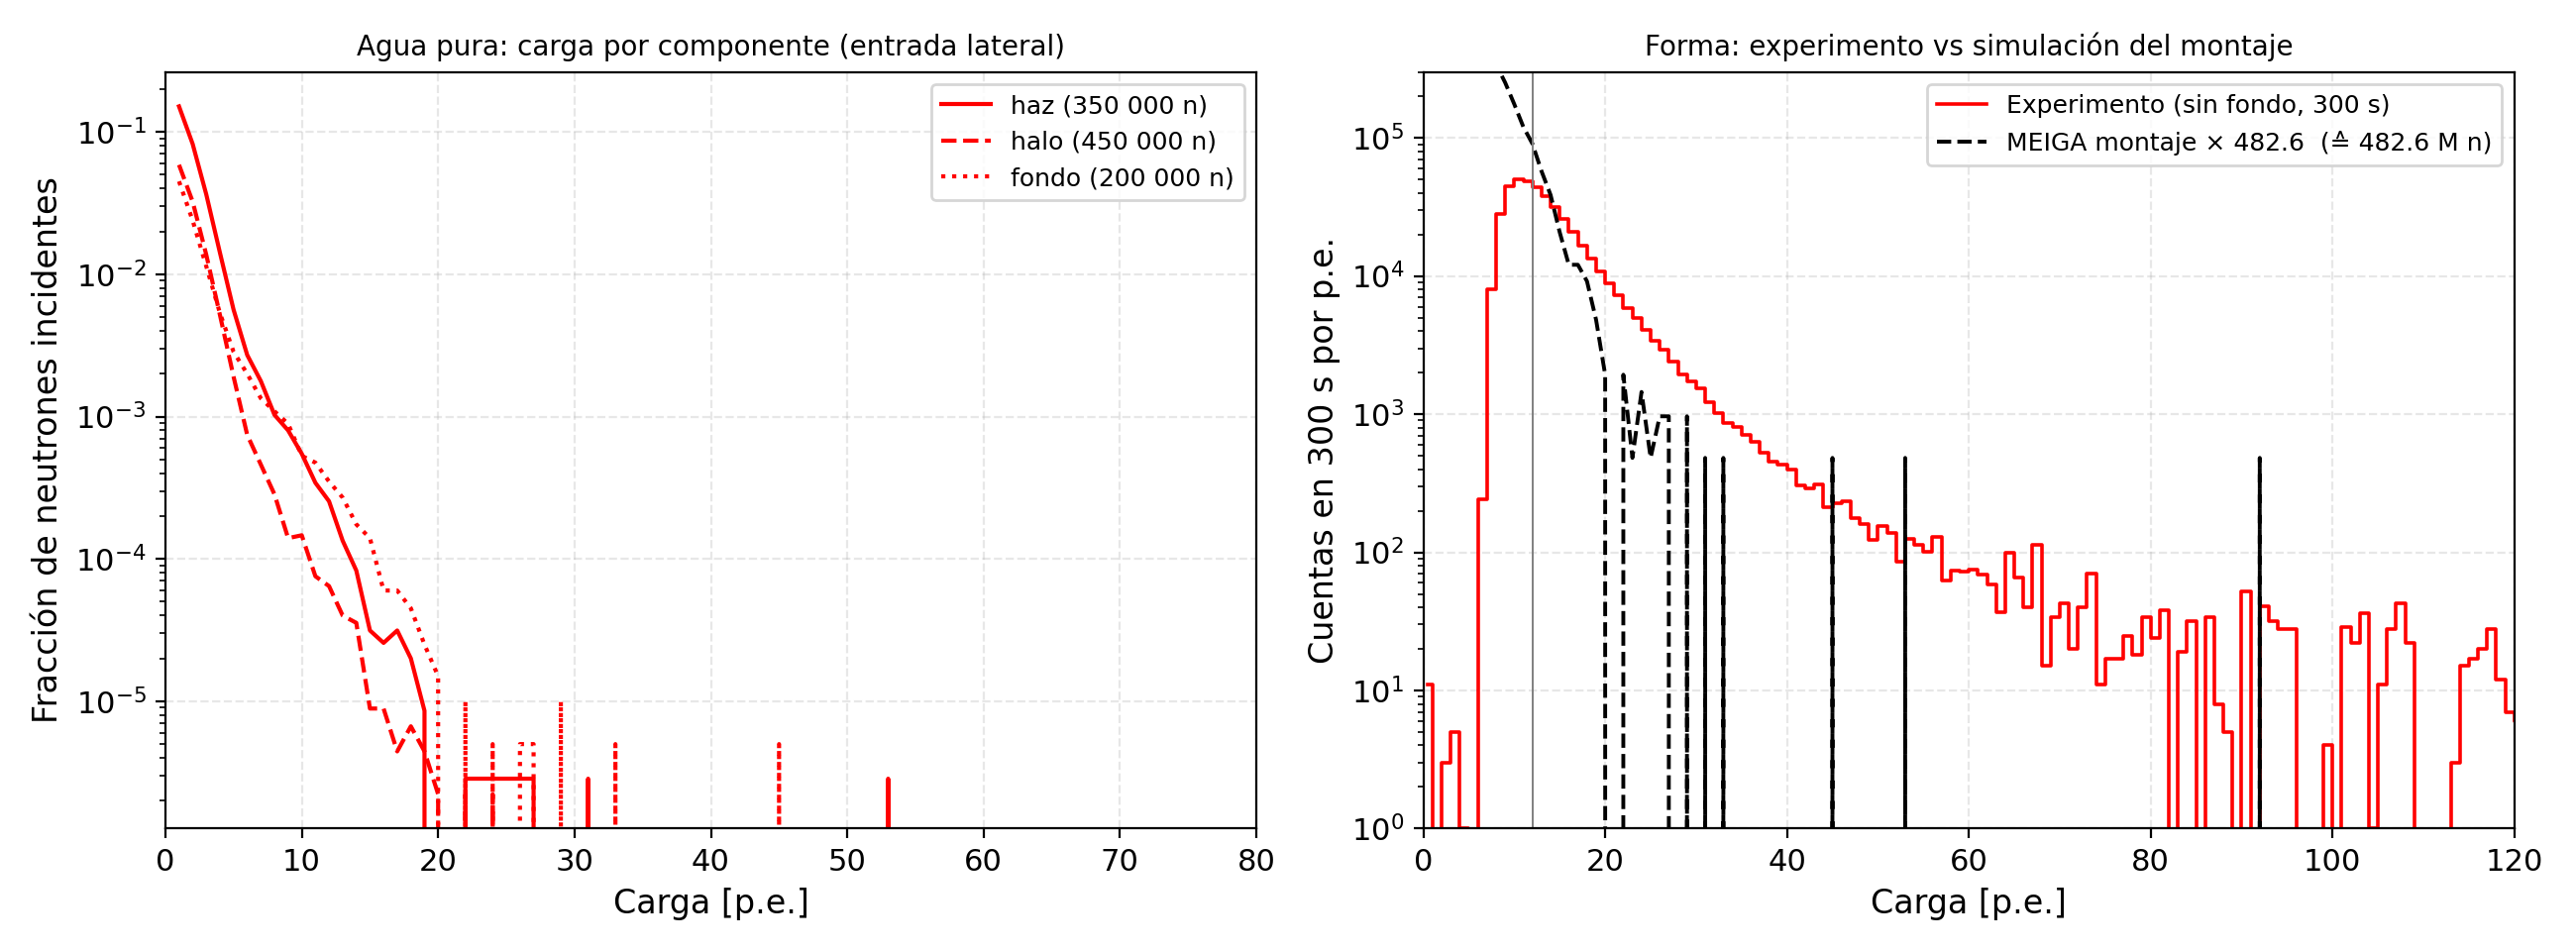

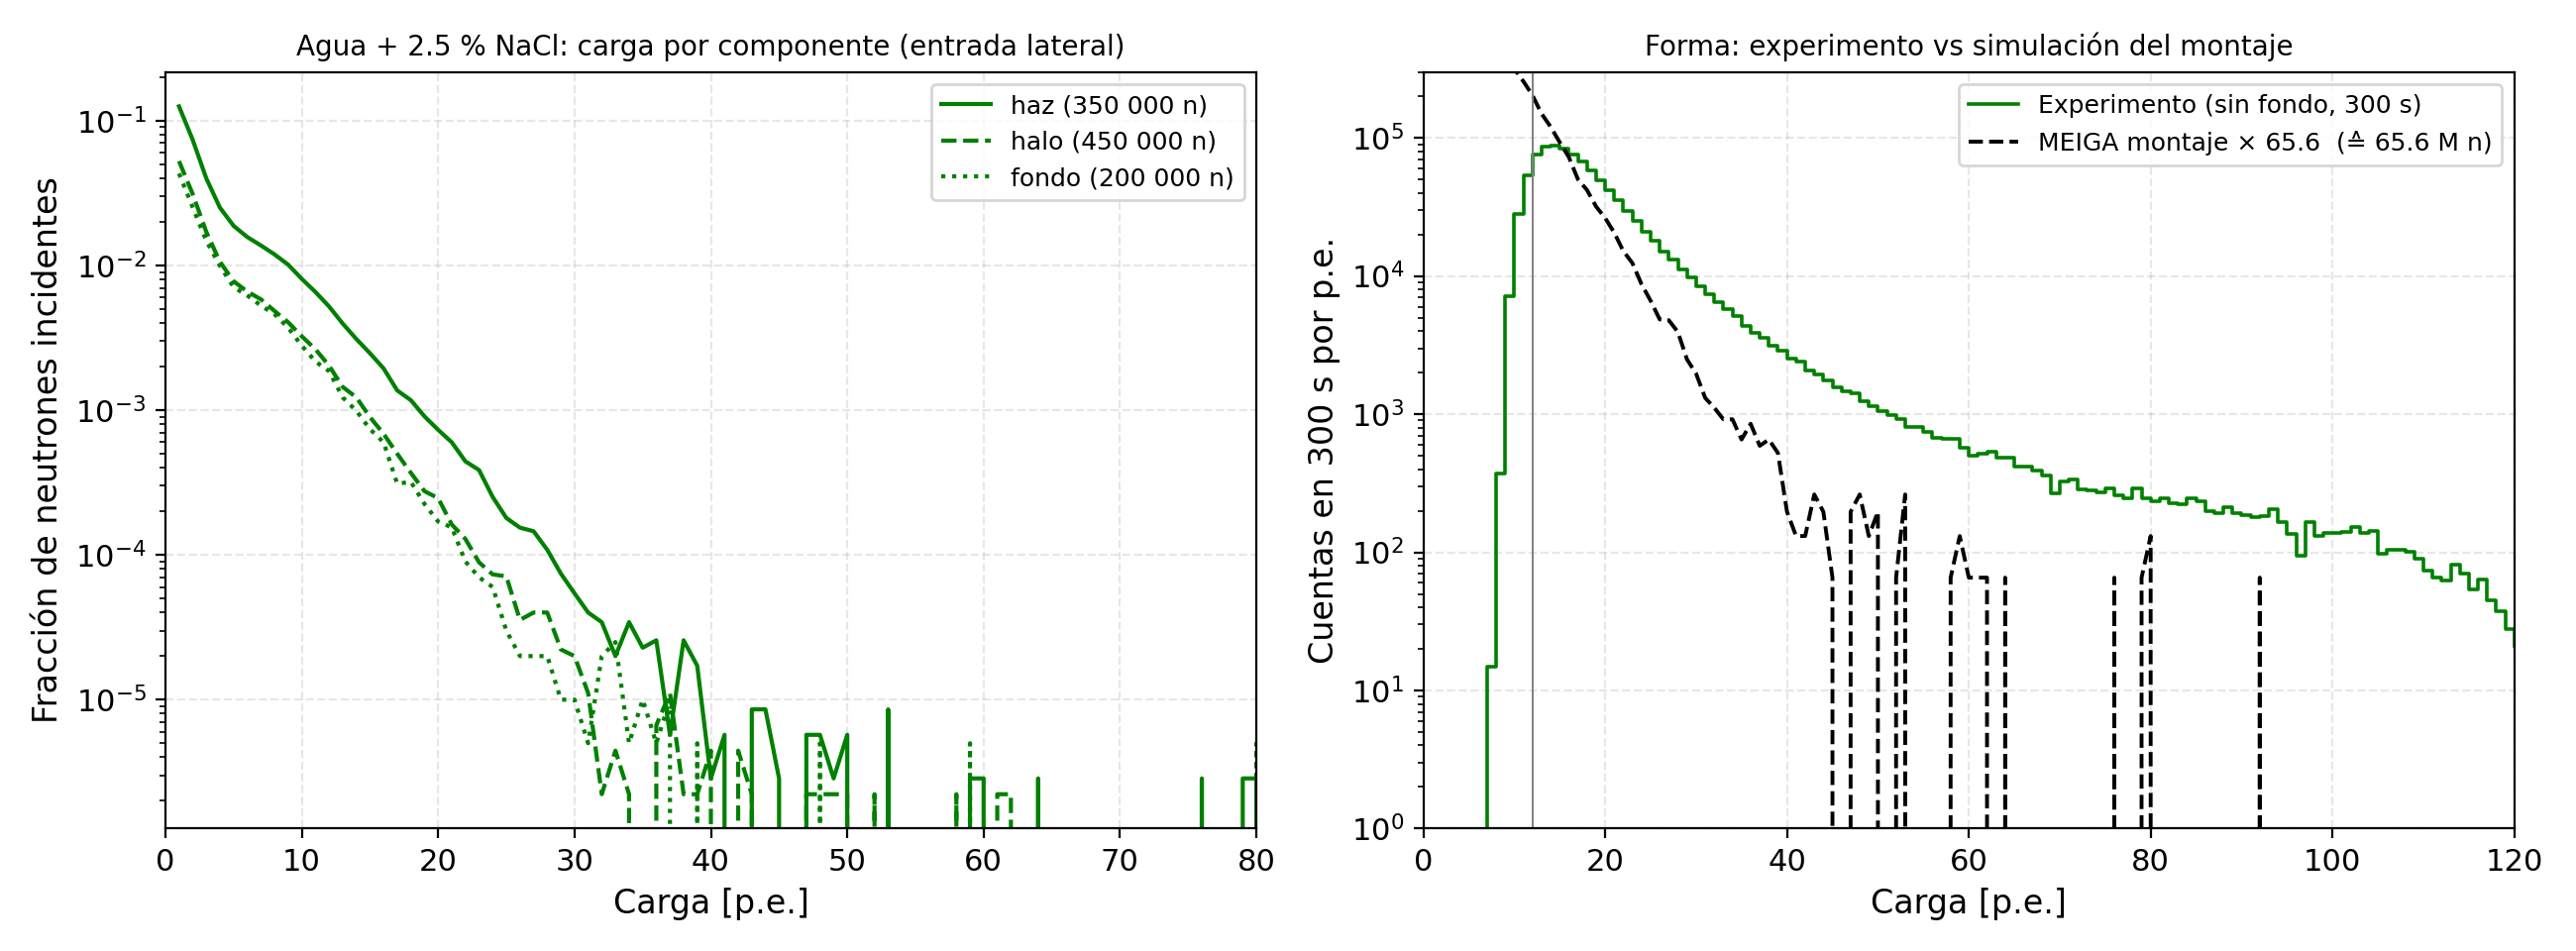

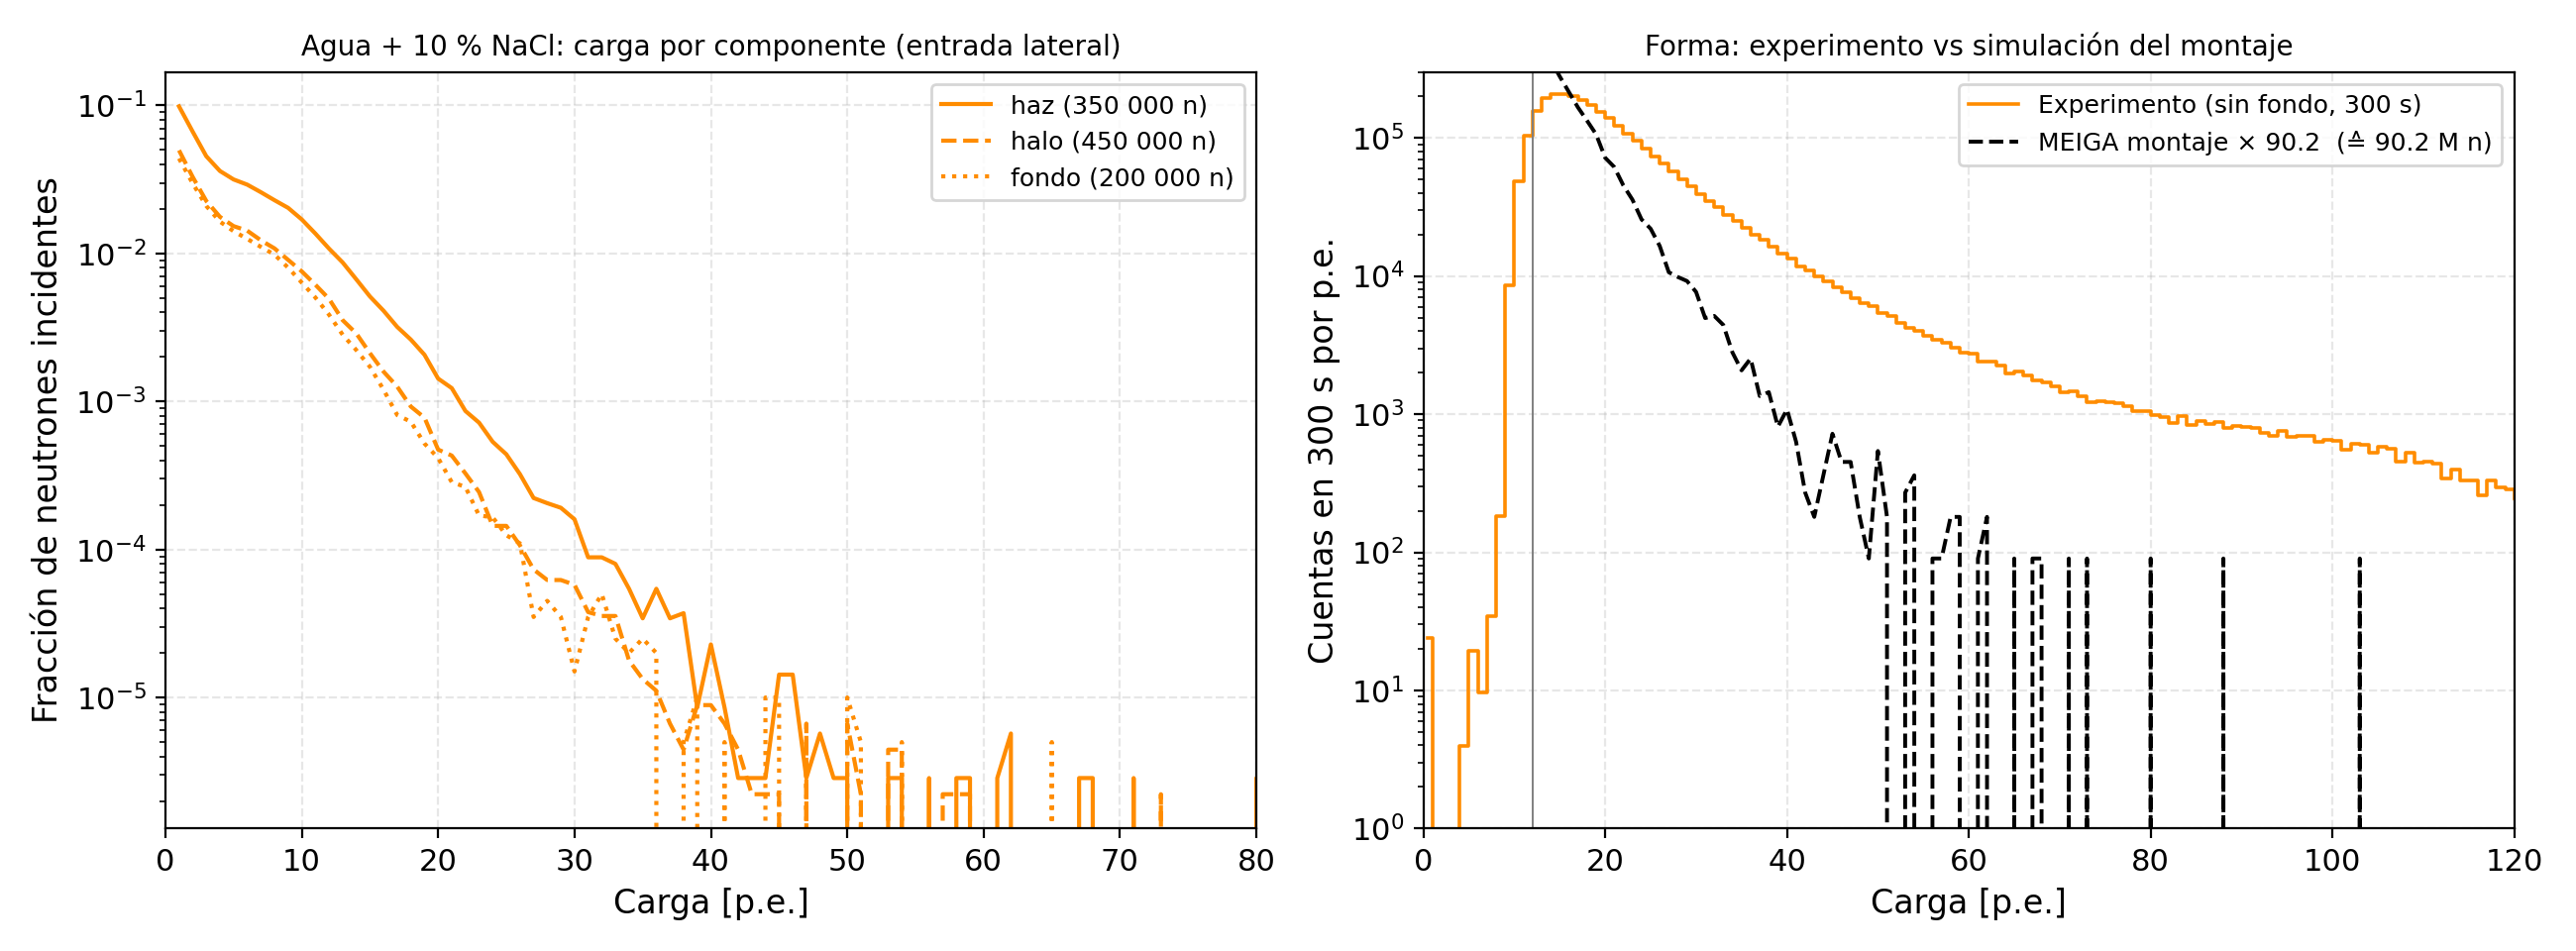

In [4]:
for m in R: display(Image(os.path.join(FIG, f"fig01_carga_{m}.png"), width=900))

## 3. Calibración con muones (VEM)

2000 μ⁻ verticales de 4 GeV/c en agua pura, mismo detector y PMT. Si el ADATA está conectado se recalcula; si no, se leen los resultados guardados.

In [5]:
MUONES = os.path.join(ADATA, "Corrida-muones-VEM-agua-pura-resultados", "2000N-muones-VEM-H2O-pura-sinSab-20261021-110157")
if os.path.isdir(MUONES):
    correr("calibrar_vem.py", MUONES)
V = json.load(open(os.path.join(RES, "calibracion_vem.json")))
print("Muones simulados:", {k: round(v, 1) for k, v in V["simulacion"].items()})
pd.DataFrame(V["calibracion"]).T.round(2)

{
 "simulacion": {
  "muones": 2000,
  "Q_media": 324.915,
  "Q_mediana": 313.0,
  "Q_pico": 304.6617647058815,
  "Q_p16": 284.0,
  "Q_p84": 362.0
 },
 "experimento_fondo": {
  "ventana_trigger_pura": {
   "pico_ADC": 40357.56154747949,
   "mediana_ADC": 38879.0
  },
  "ventana_trigger_2.5": {
   "pico_ADC": 38034.53545232279,
   "mediana_ADC": 35712.5
  },
  "ventana_trigger_10": {
   "pico_ADC": 40183.884936591414,
   "mediana_ADC": 37922.0
  },
  "robusto_pura": {
   "pico_ADC": 39458.04749340368,
   "mediana_ADC": 34866.0
  },
  "robusto_2.5": {
   "pico_ADC": 35441.955909943754,
   "mediana_ADC": 32839.0
  },
  "robusto_10": {
   "pico_ADC": 38178.145336225454,
   "mediana_ADC": 34825.0
  }
 },
 "calibracion": {
  "ventana_trigger_pura": {
   "ADC_por_pe": 132.4667753646094,
   "pe_por_1000ADC": 7.54906275364174
  },
  "ventana_trigger_2.5": {
   "ADC_por_pe": 124.84184055403566,
   "pe_por_1000ADC": 8.010135028145209
  },
  "ventana_trigger_10": {
   "ADC_por_pe": 131.89671167100

,ADC_por_pe,pe_por_1000ADC
ventana_trigger_pura,132.47,7.55
ventana_trigger_2.5,124.84,8.01
ventana_trigger_10,131.90,7.58
robusto_pura,129.51,7.72
robusto_2.5,116.33,8.60
robusto_10,125.31,7.98


Calibración por muones: 7.91 p.e./kADC (rango 7.55-8.60); usada hasta ahora: 3.95


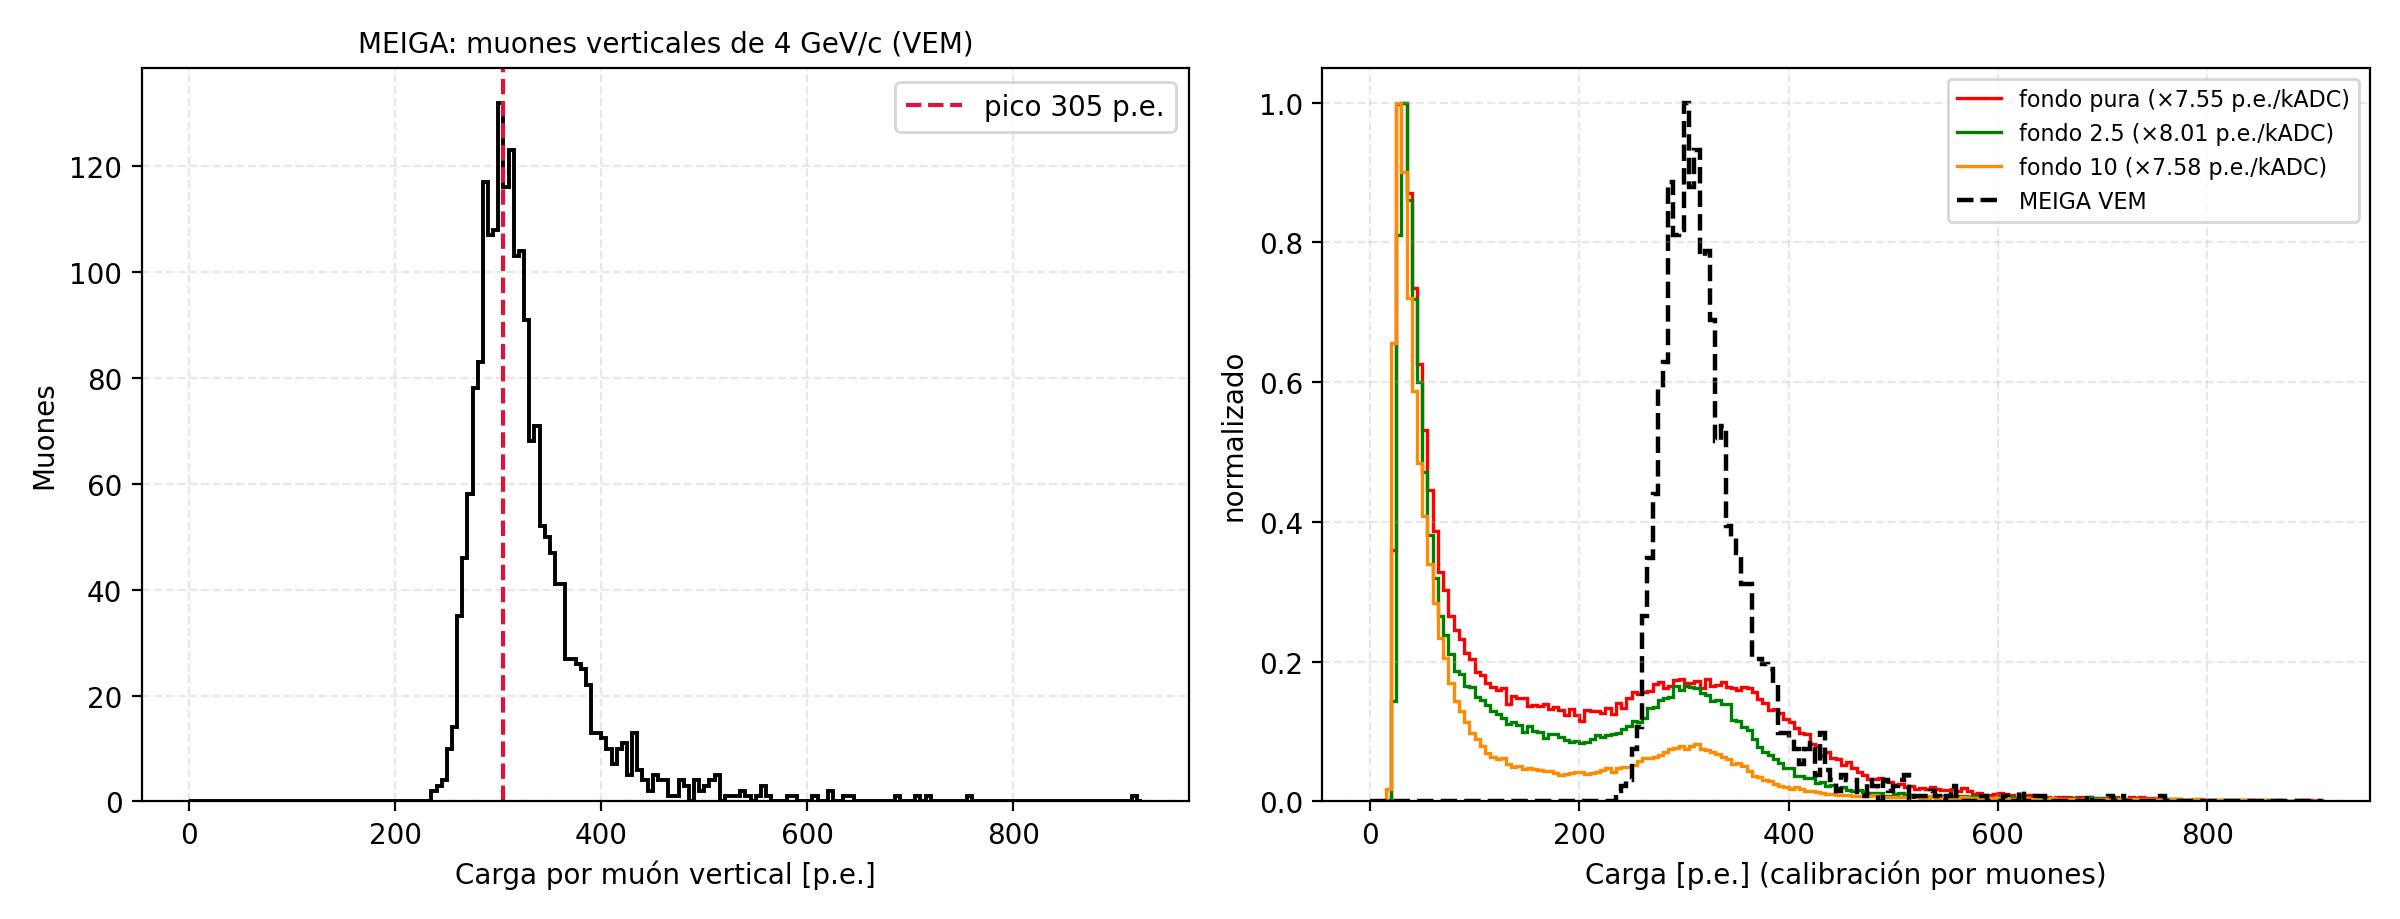

In [6]:
print("Calibración por muones: %.2f p.e./kADC (rango %.2f-%.2f); usada hasta ahora: 3.95" % (V["resumen"]["pe_por_1000ADC_media"], *V["resumen"]["rango"]))
display(Image(os.path.join(FIG, "fig05_calibracion_vem.png"), width=900))

## 4. Experimento frente a simulación con la calibración por muones

In [7]:
correr("comparar_con_calibracion_vem.py")
K = json.load(open(os.path.join(RES, "comparacion_calibracion_vem.json")))
print("Disparo ≈ 3000 ADC = %.1f p.e.;  VEM = %.0f p.e." % (K["umbral_disparo_pe"], K["VEM_pe"]))
filas = []
for met, r in K["metodos"].items():
    for p, x in r.items():
        for b in x["bandas"]:
            filas.append({"método": met, "medio": p, "banda p.e.": f"{b['pe'][0]}-{b['pe'][1]}", "fuente /s": b["fuente_por_s"], "fondo /s": b["fondo_por_s"], "cociente": b["cociente"]})
pd.DataFrame(filas).query("método == 'ventana_trigger'").pivot(index="banda p.e.", columns="medio", values="cociente").round(2)

{
 "ventana_trigger": {
  "pura": {
   "exceso_23_200pe_por_s": 376.9,
   "caida_exceso_ADC_4k_10k": 1751.3578460036867,
   "caida_exceso_ADC_10k_20k": 3137.798888157447,
   "sim": {
    "caida_pe_2_8": 1.2770946345086955,
    "fraccion_Q_ge_umbral": 1.5e-05,
    "eventos_300s_Q_ge_umbral": 5.597931111111111,
    "pe_por_1000ADC_por_forma": 0.7292025655538171
   },
   "exceso_sobre_sim_Q_ge_umbral": 20198.533664619747
  },
  "2.5": {
   "exceso_23_200pe_por_s": 1898.596287625418,
   "caida_exceso_ADC_4k_10k": 1911.3184004875907,
   "caida_exceso_ADC_10k_20k": 4120.250352430015,
   "sim": {
    "caida_pe_2_8": 3.0652971521464334,
    "fraccion_Q_ge_umbral": 0.000668,
    "eventos_300s_Q_ge_umbral": 249.4098666666667,
    "pe_por_1000ADC_por_forma": 1.6037606038661347
   },
   "exceso_sobre_sim_Q_ge_umbral": 2283.7063100188448
  },
  "10": {
   "exceso_23_200pe_por_s": 7213.728149386845,
   "caida_exceso_ADC_4k_10k": 2331.8564465272166,
   "caida_exceso_ADC_10k_20k": 3804.6006752195244,


medio,10,2.5,pura
banda p.e.,,,
0-23,7.77,8.97,6.00
100-200,6.50,2.31,1.18
200-280,2.14,1.22,1.02
23-50,27.03,17.29,5.79
280-400,1.14,1.04,1.02
400-800,1.20,1.01,1.05
50-100,19.58,9.08,2.65


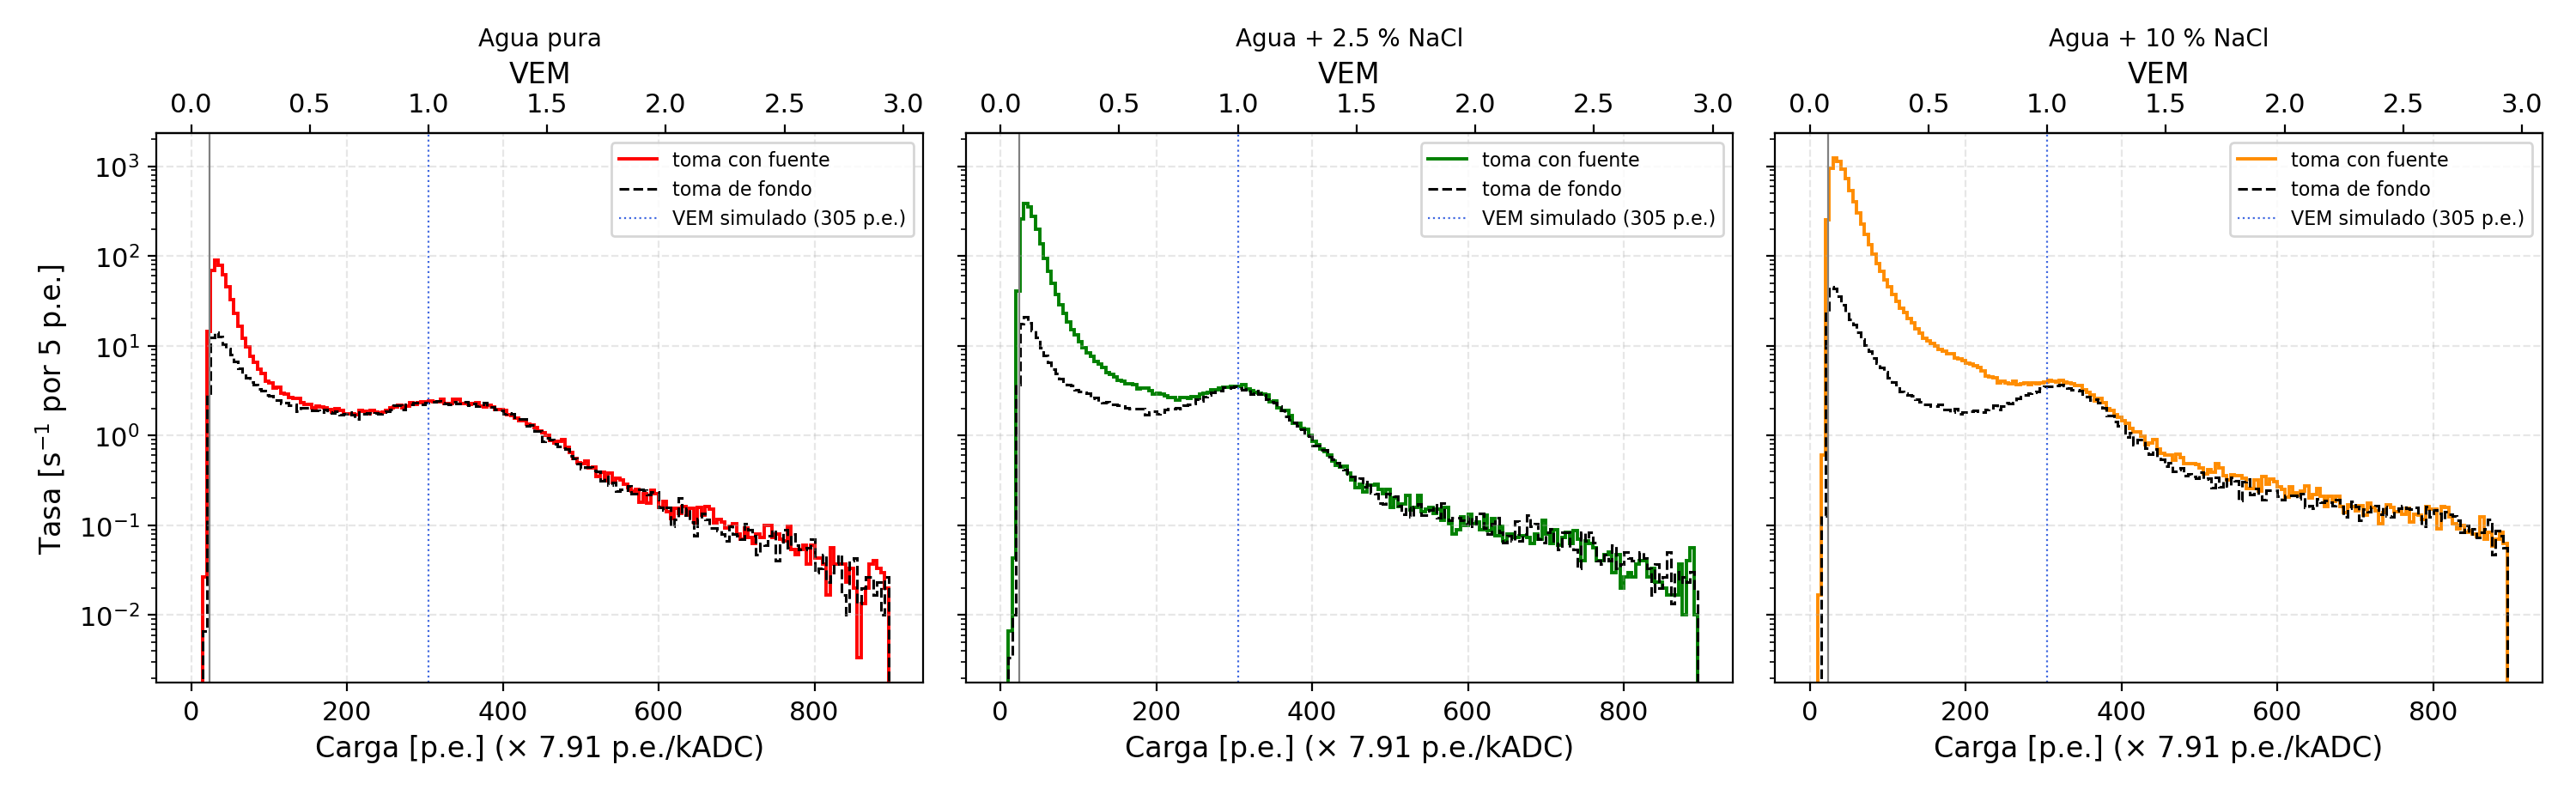

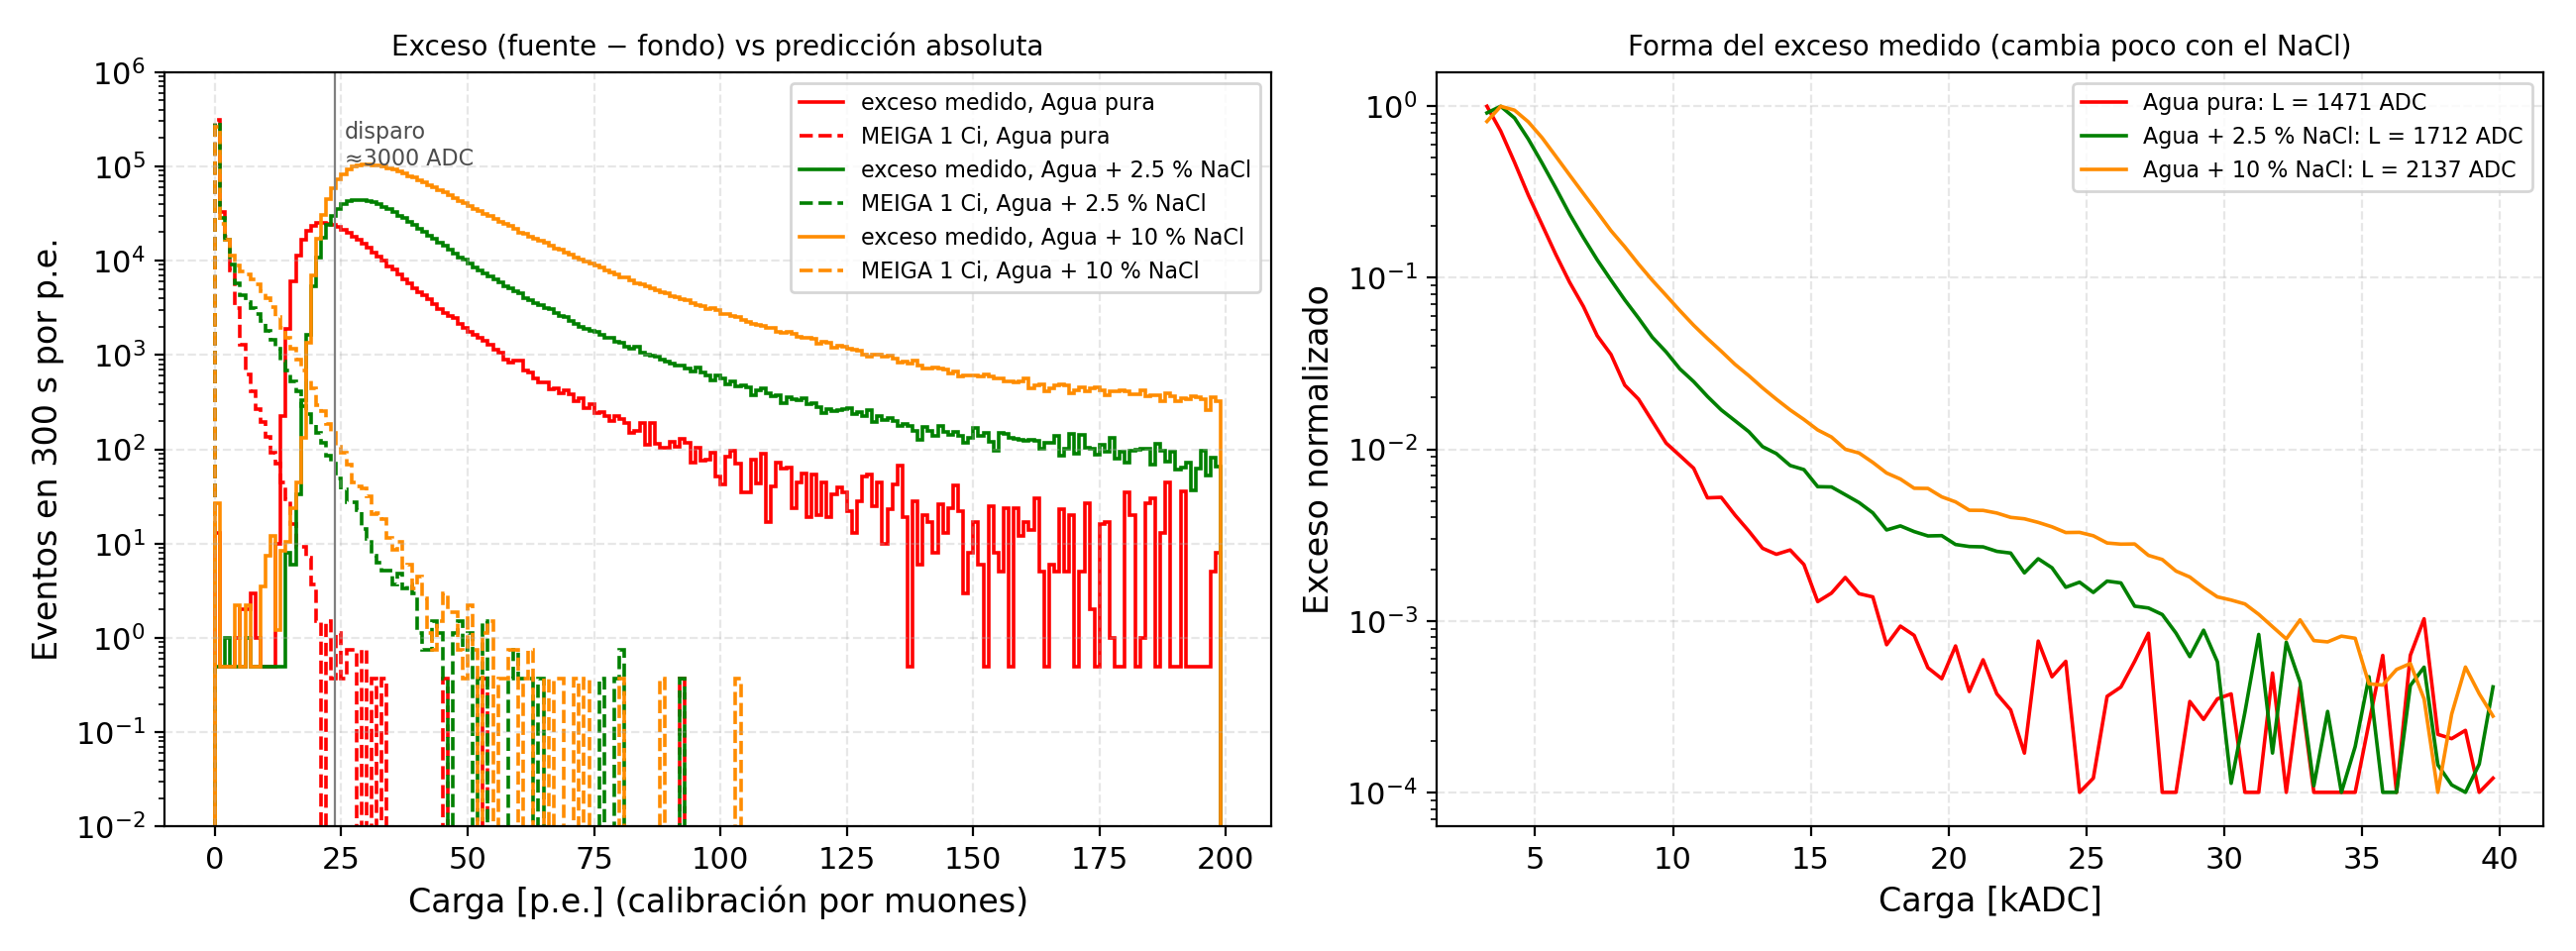

ventana_trigger                     robusto           \
                                    pura      2.5       10      pura      2.5   
exceso 23-200 p.e. /s             376.90  1898.60  7213.73    941.03  3076.67   
L_exp ADC                        1751.36  1911.32  2331.86   1470.65  1712.09   
MEIGA Q>=disparo (300 s)            5.60   249.41   556.30      5.60   249.41   
medido/MEIGA                    20198.53  2283.71  3890.21  50430.95  3700.74   
L_sim p.e.                          1.28     3.07     5.53      1.28     3.07   

                                   
                               10  
exceso 23-200 p.e. /s     9354.95  
L_exp ADC                 2136.56  
MEIGA Q>=disparo (300 s)   556.30  
medido/MEIGA              5044.93  
L_sim p.e.                   5.53

In [8]:
display(Image(os.path.join(FIG, "fig07_bandas_fuente_fondo.png"), width=1000))
display(Image(os.path.join(FIG, "fig08_exceso_vs_meiga.png"), width=1000))
pd.DataFrame({(met, p): {"exceso 23-200 p.e. /s": x["exceso_23_200pe_por_s"], "L_exp ADC": x["caida_exceso_ADC_4k_10k"],
               "MEIGA Q>=disparo (300 s)": x.get("sim", {}).get("eventos_300s_Q_ge_umbral"), "medido/MEIGA": x.get("exceso_sobre_sim_Q_ge_umbral"),
               "L_sim p.e.": x.get("sim", {}).get("caida_pe_2_8")} for met, r in K["metodos"].items() for p, x in r.items()}).round(2)

## 5. Calibración por consistencia entre medios

{
 "ventana_trigger": {
  "pura/2.5": {
   "3000": [
    null,
    8.84659518010031,
    null
   ],
   "4000": [
    null,
    6.625222402899344,
    null
   ],
   "5000": [
    12.829168150561406,
    2.7187644435346434,
    {
     "pura": 54030000000.0,
     "nacl25": 58294127090.301
    }
   ],
   "6000": [
    10.668204630900101,
    2.3153753697747845,
    {
     "pura": 31173000000.0,
     "nacl25": 35005036789.29765
    }
   ]
  },
  "pura/10": {
   "3000": [
    null,
    5.196068485512457,
    null
   ],
   "4000": [
    10.533286418045666,
    3.863381783887271,
    {
     "pura": 29087333333.33333,
     "nacl10": 29573587523.38303
    }
   ],
   "5000": [
    8.215211494395575,
    1.2127454617439748,
    {
     "pura": 18010000000.0,
     "nacl10": 19401592741.935482
    }
   ],
   "6000": [
    6.668679422162912,
    0.688160059113865,
    {
     "pura": 10391000000.0,
     "nacl10": 11488890625.757357
    }
   ]
  }
 },
 "robusto": {
  "pura/2.5": {
   "3000": [
    null,

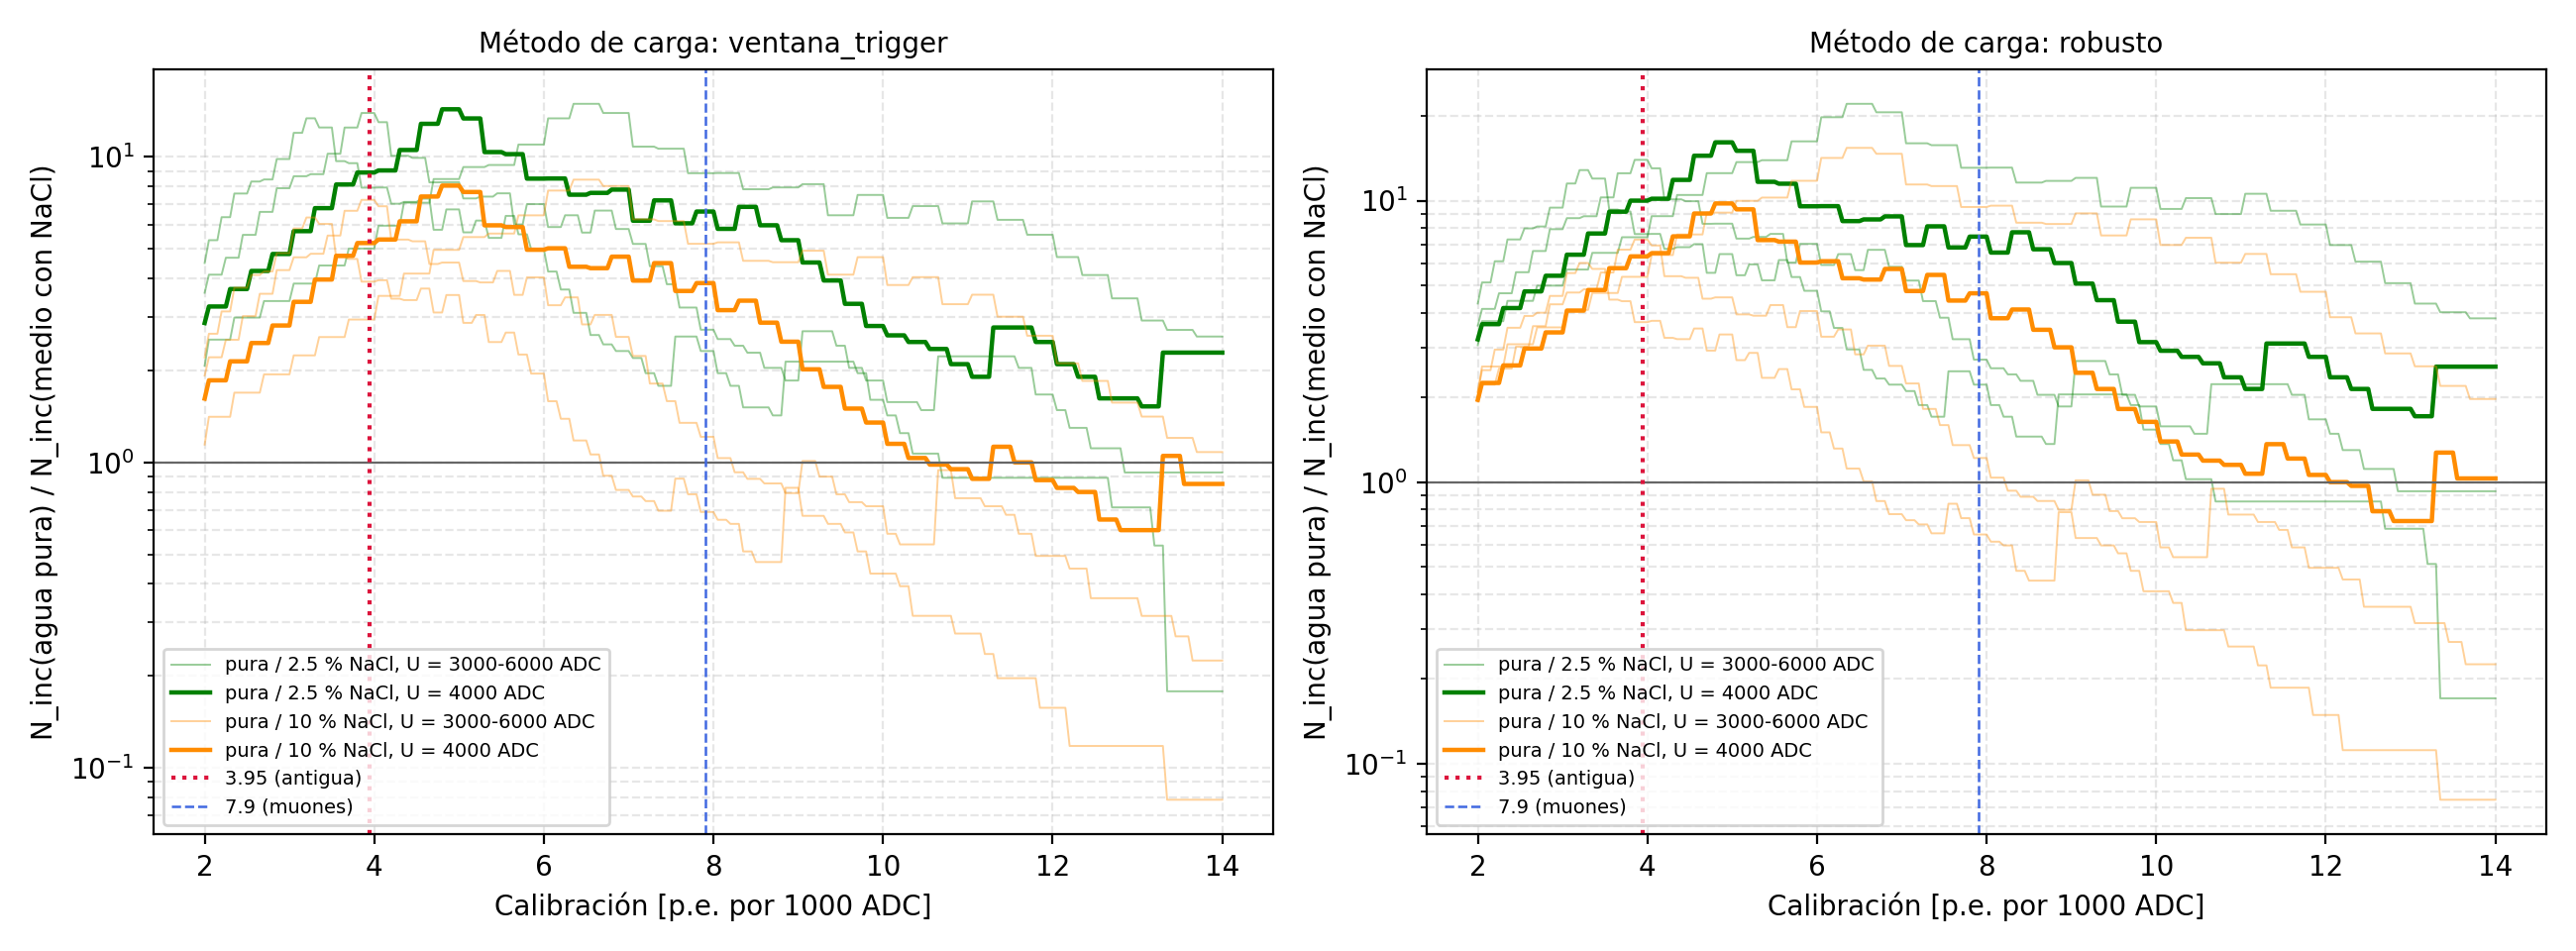

In [9]:
correr("calibracion_por_consistencia.py")
display(Image(os.path.join(FIG, "fig06_calibracion_consistencia.png"), width=1000))

## 5b. Método de los cuadernos del prototipo (factores comunes)

Un factor horizontal (ADC por p.e., ganancia del PMT) y uno vertical (neutrones incidentes), **iguales para los tres medios**.
`comparacion_metodo_cuaderno.py` reproduce la figura del cuaderno `Comparacion-datos-simulado.ipynb` (simulación térmica, 253 ADC/p.e., ×10, agua pura −1500 ADC),
aplica los mismos factores al montaje y muestra el montaje con el factor común ajustado por `ajuste_factor_comun.py`.

{
 "k_muones_ADC_por_pe": 126.48054599563302,
 "N_modelo_5min": 373272,
 "ventana_trigger": {
  "k_ADC_por_pe": 1050.0,
  "pe_por_1000ADC": 0.9523809523809523,
  "N_inc_300s": 4722126.742368431,
  "rms_ln": 0.8185556767032507,
  "N_inc_propio_con_k_comun": {
   "pura": 7508698.5659962995,
   "2.5": 2697432.242444426,
   "10": 5745697.396316695
  },
  "N_inc_sobre_modelo_1Ci": 12.650632092330609,
  "bins_con_simulacion_si_k_muones": 43
 },
 "robusto": {
  "k_ADC_por_pe": 975.0,
  "pe_por_1000ADC": 1.0256410256410255,
  "N_inc_300s": 6593689.740818936,
  "rms_ln": 0.8704481008503866,
  "N_inc_propio_con_k_comun": {
   "pura": 11270849.78297383,
   "2.5": 3612308.0066808104,
   "10": 7699256.369681456
  },
  "N_inc_sobre_modelo_1Ci": 17.66457098528402,
  "bins_con_simulacion_si_k_muones": 43
 }
}
 


{
 "factores_cuaderno": {
  "ADC_por_pe": 253.1645569620253,
  "altura": 10.0,
  "desplazamiento_pura_ADC": 1500.0
 },
 "pura": {
  "exp_neto_total_cuentas": 114435,
  "sim_montaje_Qmedia": 1.9514408661219071
 },
 "2.5": {
  "exp_neto_total_cuentas": 574844,
  "sim_montaje_Qmedia": 3.9324134034316387
 },
 "10": {
  "exp_neto_total_cuentas": 1730564,
  "sim_montaje_Qmedia": 5.297350267595406
 },
 "sim_cuaderno": {
  "Agua pura": {
   "N_Q_ge_1": 23418.0,
   "Q_media": 3.694722008711248
  },
  "Agua + 2.5 % NaCl": {
   "N_Q_ge_1": 30722.0,
   "Q_media": 7.714992513508236
  },
  "Agua + 10 % NaCl": {
   "N_Q_ge_1": 44021.0,
   "Q_media": 10.576372640330751
  }
 }
}
 


,ventana_trigger,robusto
ADC/p.e.,1050.000,975.000
p.e./kADC,0.952,1.026
N_inc (300 s),4722126.742,6593689.741
N / modelo 1 Ci,12.651,17.665
rms ln,0.819,0.870


Calibración por muones: 126.5 ADC/p.e.


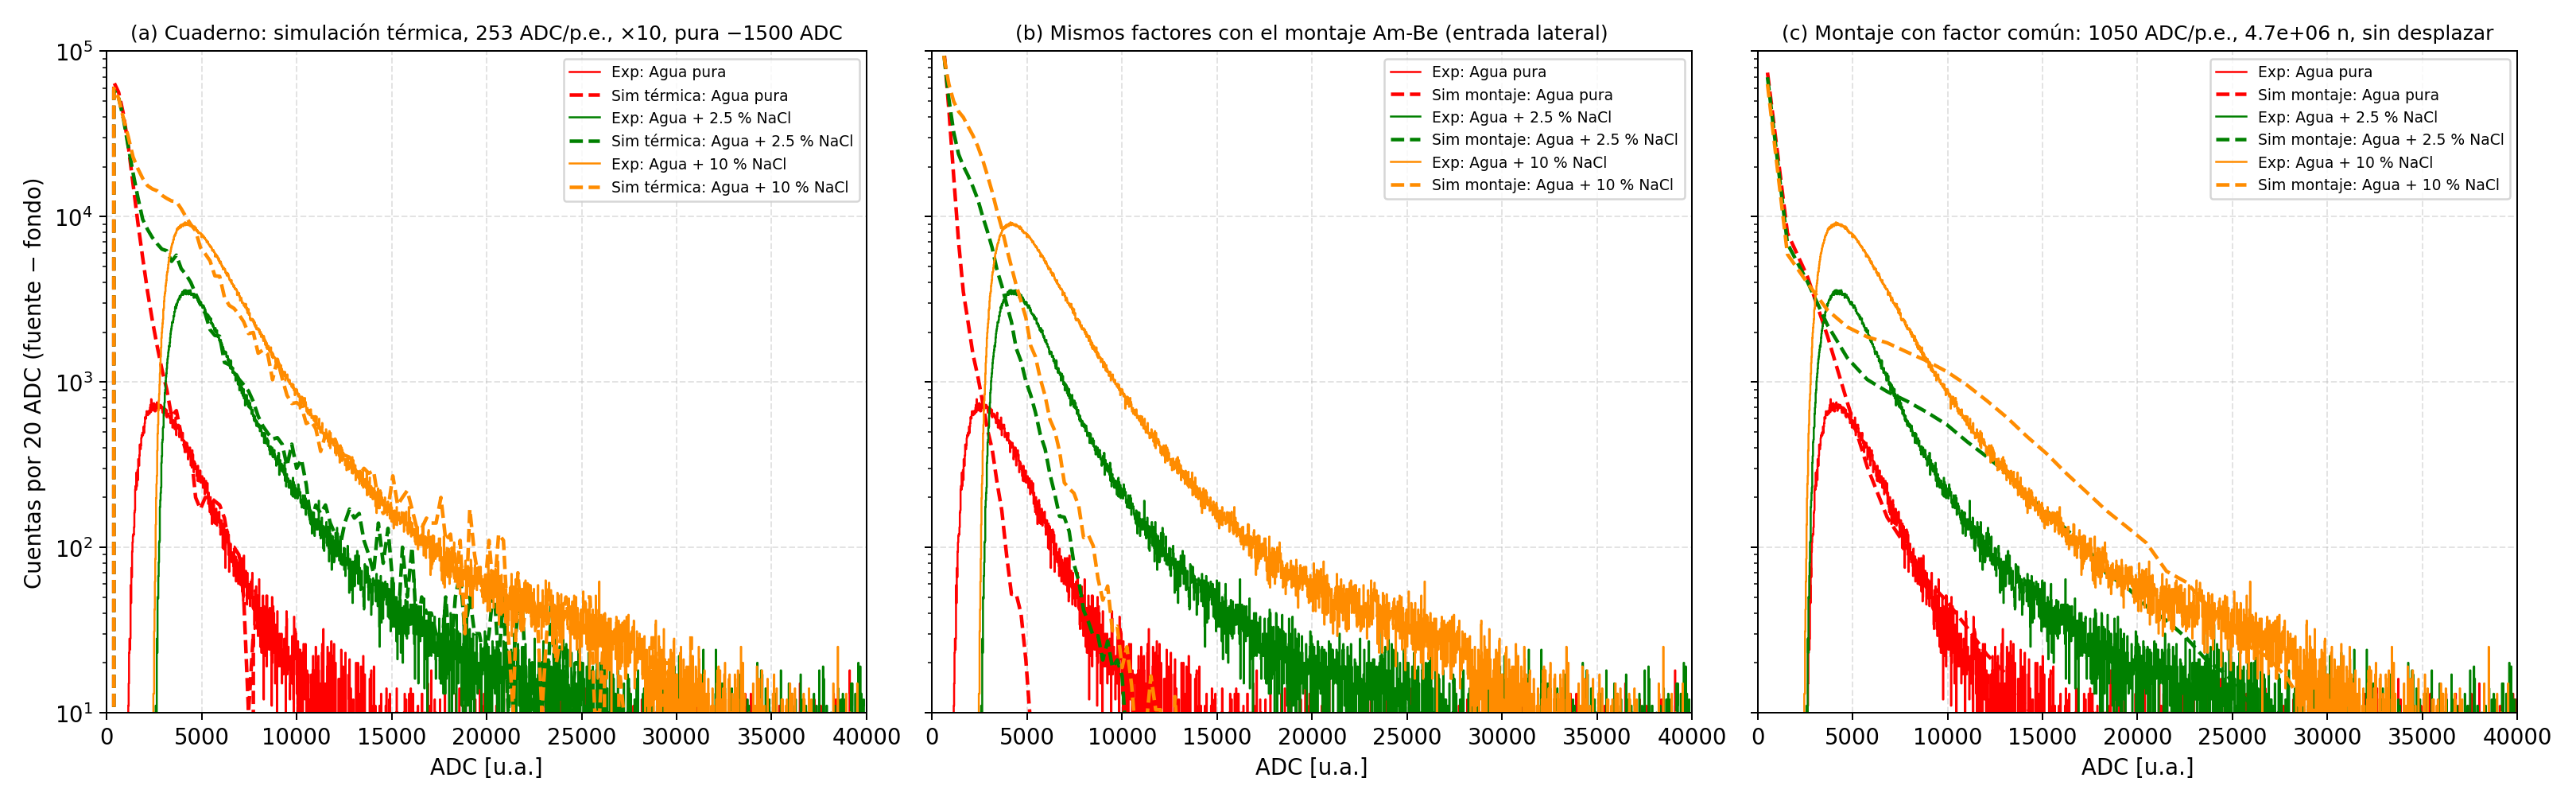

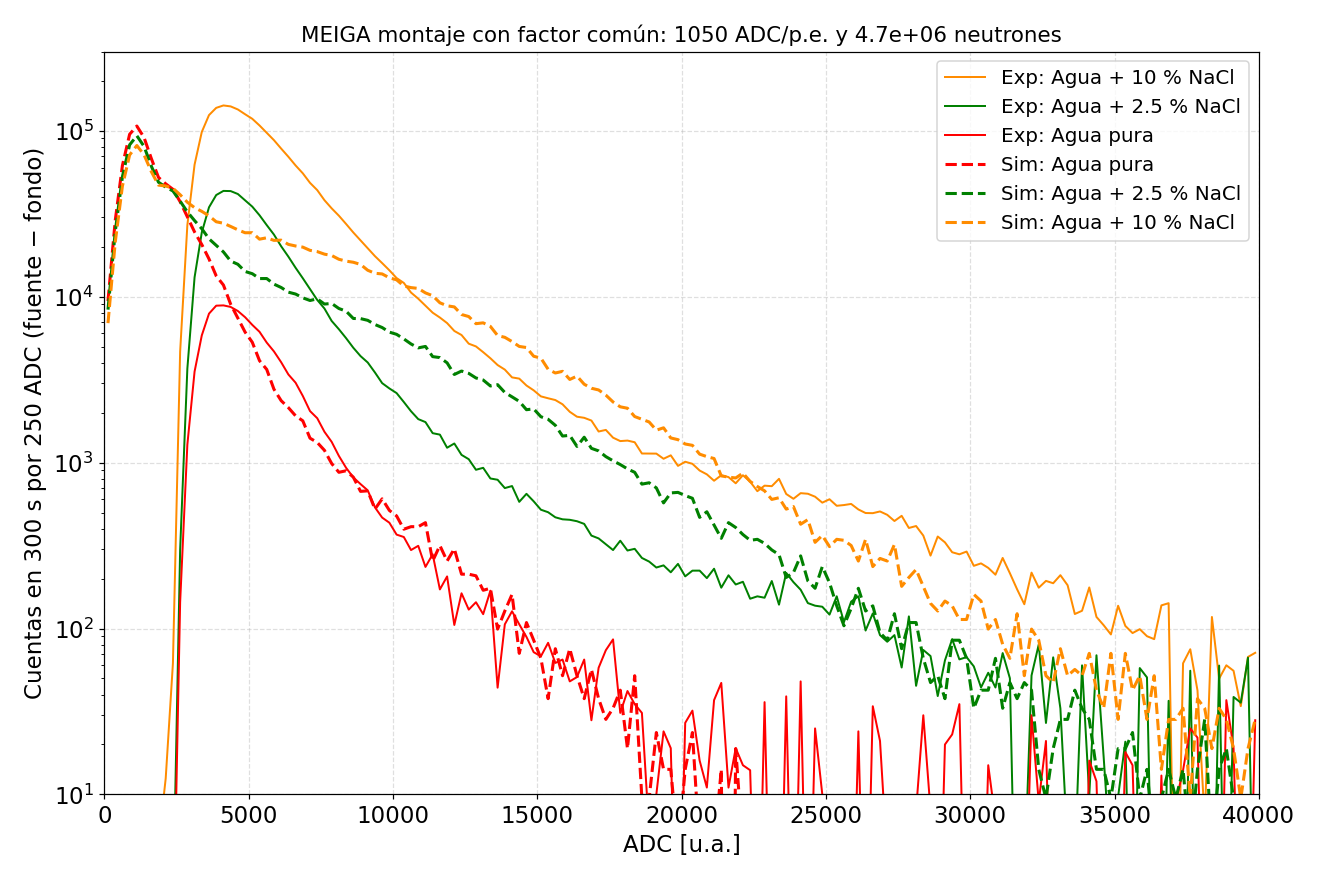

In [10]:
correr("ajuste_factor_comun.py")
correr("comparacion_metodo_cuaderno.py")
A = json.load(open(os.path.join(RES, "ajuste_factor_comun.json")))
display(pd.DataFrame({m: {"ADC/p.e.": A[m]["k_ADC_por_pe"], "p.e./kADC": A[m]["pe_por_1000ADC"], "N_inc (300 s)": A[m]["N_inc_300s"],
                          "N / modelo 1 Ci": A[m]["N_inc_sobre_modelo_1Ci"], "rms ln": A[m]["rms_ln"]} for m in ("ventana_trigger", "robusto")}).round(3))
print("Calibración por muones:", round(A["k_muones_ADC_por_pe"], 1), "ADC/p.e.")
display(Image(os.path.join(FIG, "fig11_metodo_cuaderno.png"), width=1100))
display(Image(os.path.join(FIG, "fig10b_histogramas_factor_comun.png"), width=800))

## 5c. Corridas de la Campaña 1 (inyección por la tapa, 1 meV – 1 keV) con factores comunes

Un factor horizontal común a todas las energías y medios; factor vertical (neutrones) libre por energía. Necesita `Carga/` (o la variable `CARGA_CAMPANA1`).

k global = 450.0 ADC/p.e.
   1 meV: k=   525  N=7.75e+06  rms=0.75 | global: N=1.01e+07 rms=0.77 | <Q> pura=3.20 2.5=7.67 10=10.49
 2.5 meV: k=   575  N=6.03e+06  rms=0.71 | global: N=8.98e+06 rms=0.72 | <Q> 2.5=7.61 10=10.40 pura=3.23
   5 meV: k=   450  N=8.09e+06  rms=0.74 | global: N=8.09e+06 rms=0.74 | <Q> 2.5=7.62 pura=3.17 10=10.51
   7 meV: k=   450  N=7.77e+06  rms=0.73 | global: N=7.77e+06 rms=0.73 | <Q> pura=3.18 10=10.51 2.5=7.64
  10 meV: k=   450  N=7.49e+06  rms=0.74 | global: N=7.49e+06 rms=0.74 | <Q> 2.5=7.69 pura=3.20 10=10.38
  25 meV: k=   500  N=5.47e+06  rms=0.71 | global: N=6.59e+06 rms=0.73 | <Q> pura=3.21 2.5=7.37 10=10.46
  50 meV: k=   475  N=5.71e+06  rms=0.71 | global: N=6.28e+06 rms=0.71 | <Q> pura=3.20 10=10.42 2.5=7.42
  80 meV: k=   475  N=5.52e+06  rms=0.71 | global: N=6.13e+06 rms=0.71 | <Q> pura=3.16 10=10.55 2.5=7.47
 100 meV: k=   400  N=7.2e+06  rms=0.71 | global: N=5.83e+06 rms=0.71 | <Q> pura=3.19 10=10.57 2.5=7.50
 300 meV: k=   450  N=5.64e+06

,k por energía,N (k por energía),N (k global),rms (k global)
1 meV,525.0,7748780.329,1.010846e+07,0.767
2.5 meV,575.0,6027972.162,8.981397e+06,0.715
5 meV,450.0,8090680.849,8.090681e+06,0.741
7 meV,450.0,7774296.908,7.774297e+06,0.729
10 meV,450.0,7492368.710,7.492369e+06,0.741
25 meV,500.0,5469266.039,6.589972e+06,0.732
50 meV,475.0,5707328.035,6.279857e+06,0.713
80 meV,475.0,5516064.079,6.133608e+06,0.711
100 meV,400.0,7200265.423,5.825337e+06,0.712
300 meV,450.0,5641369.961,5.641370e+06,0.725


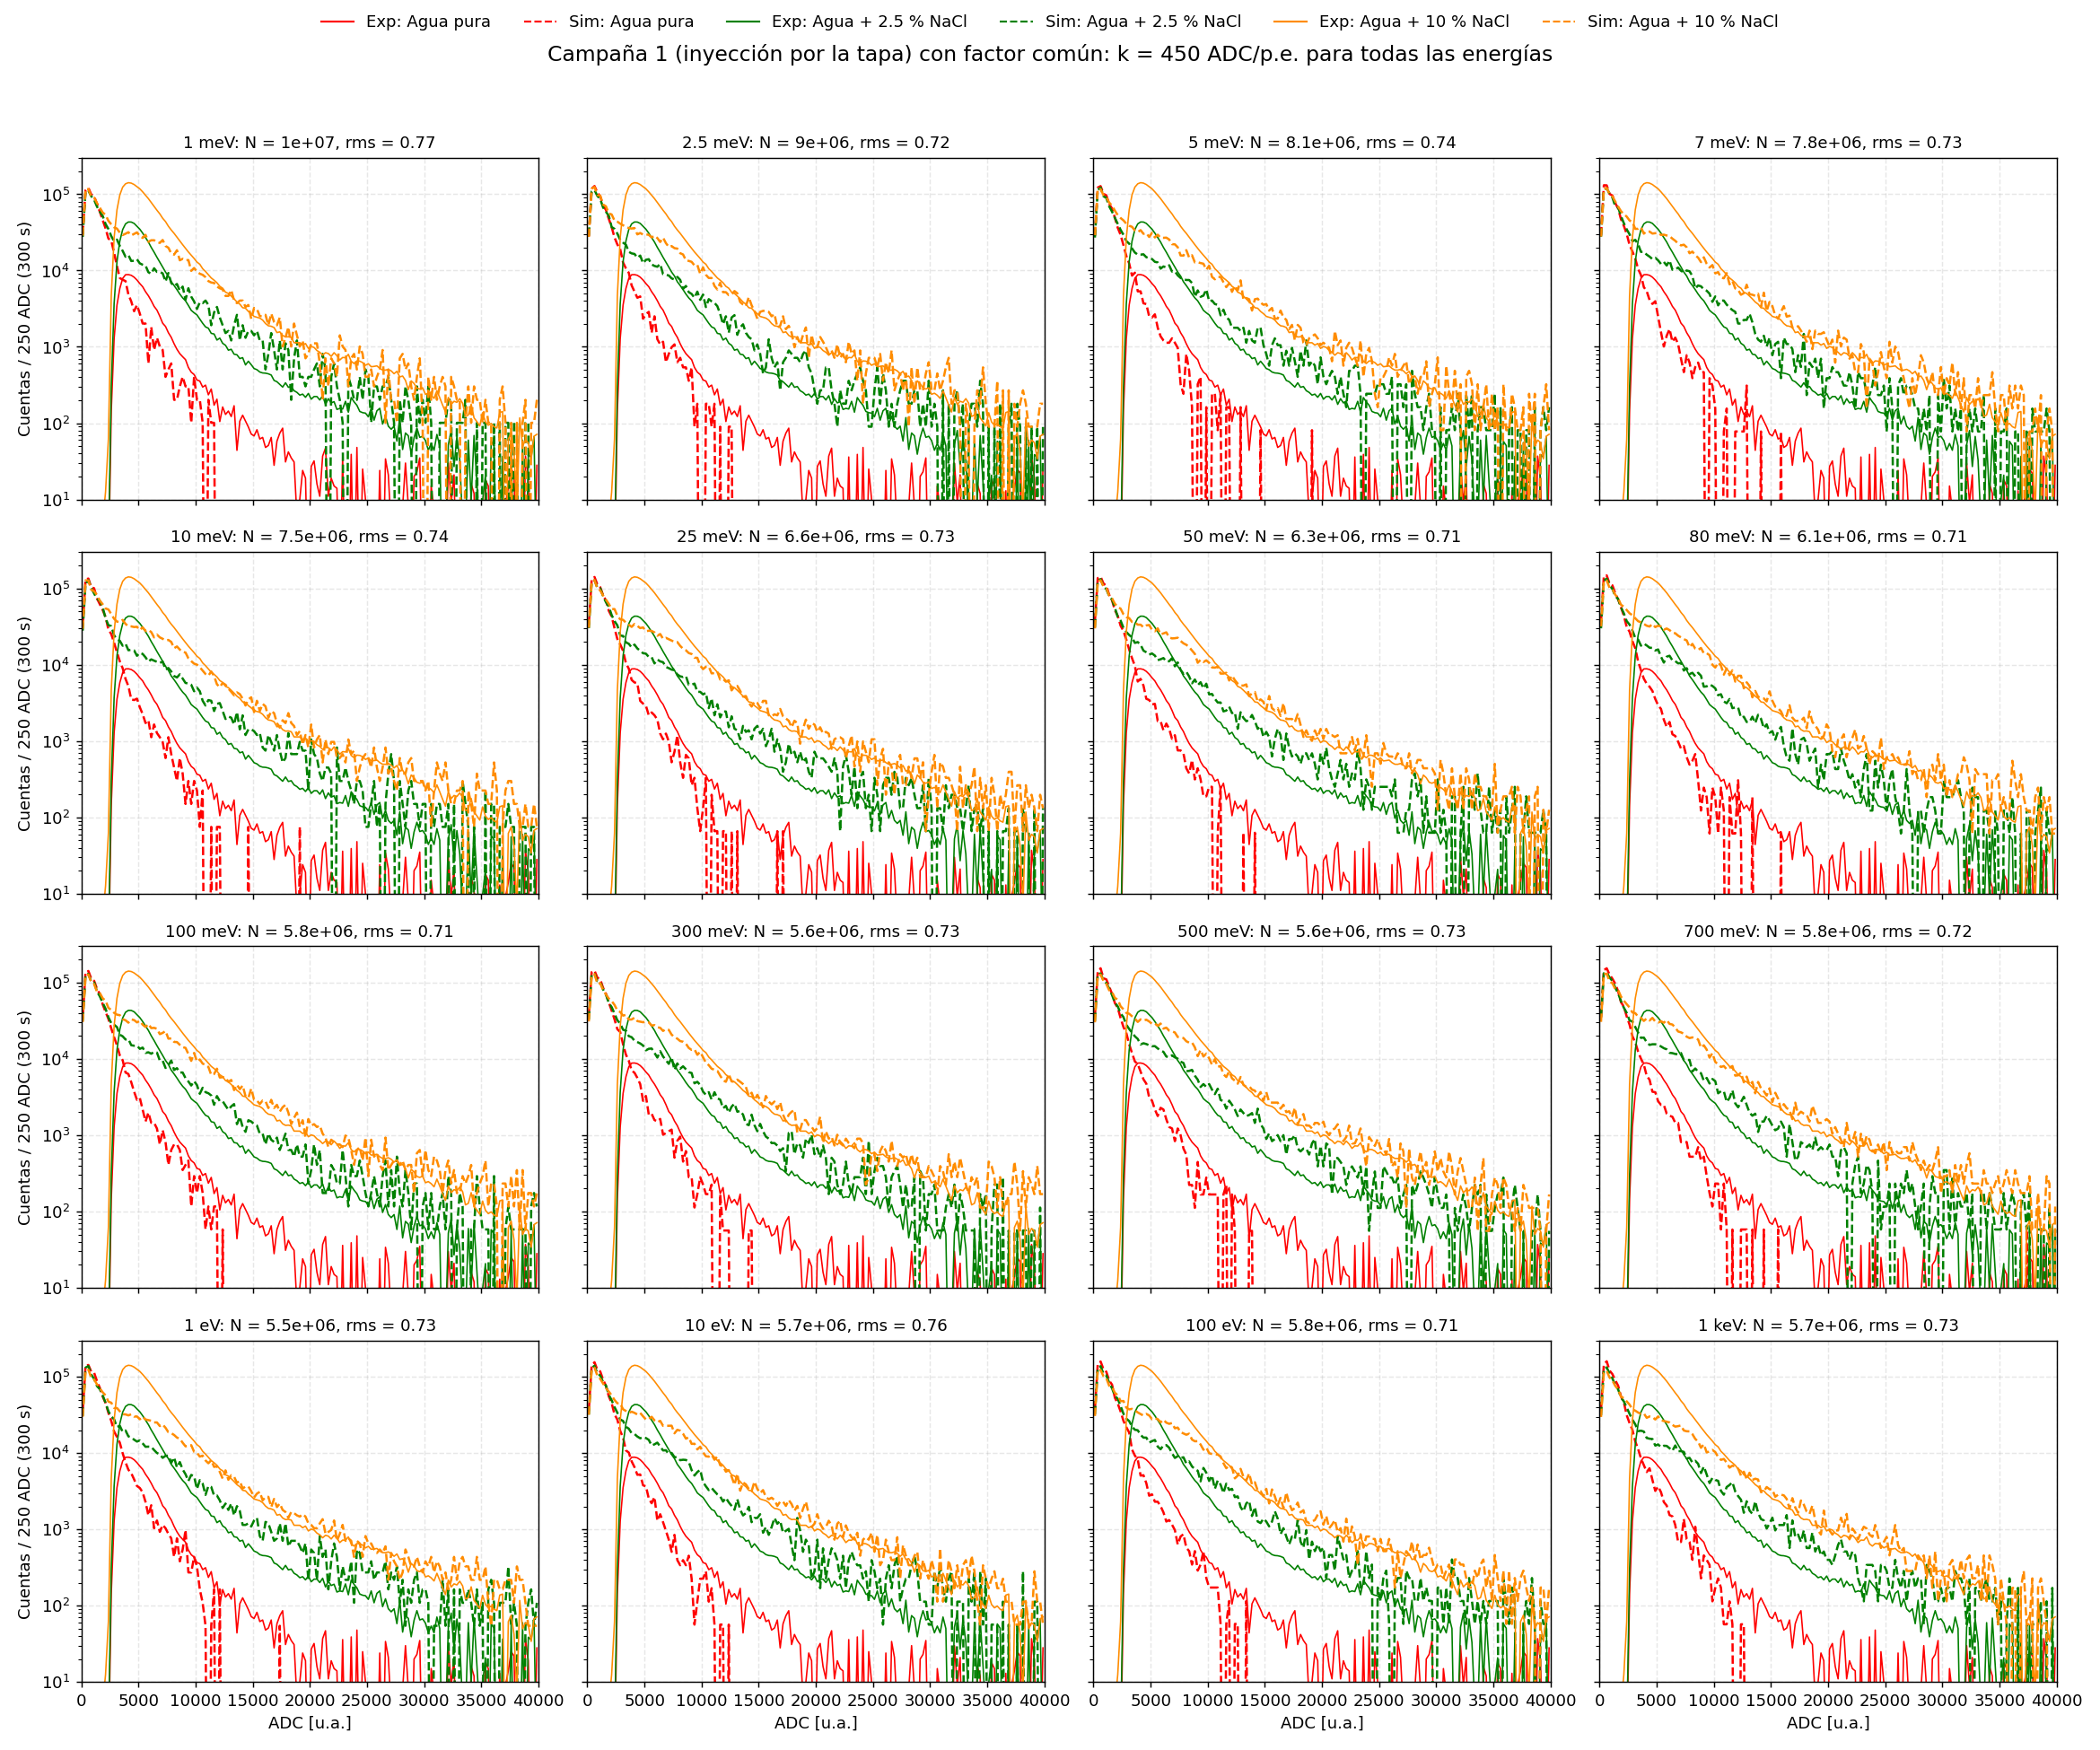

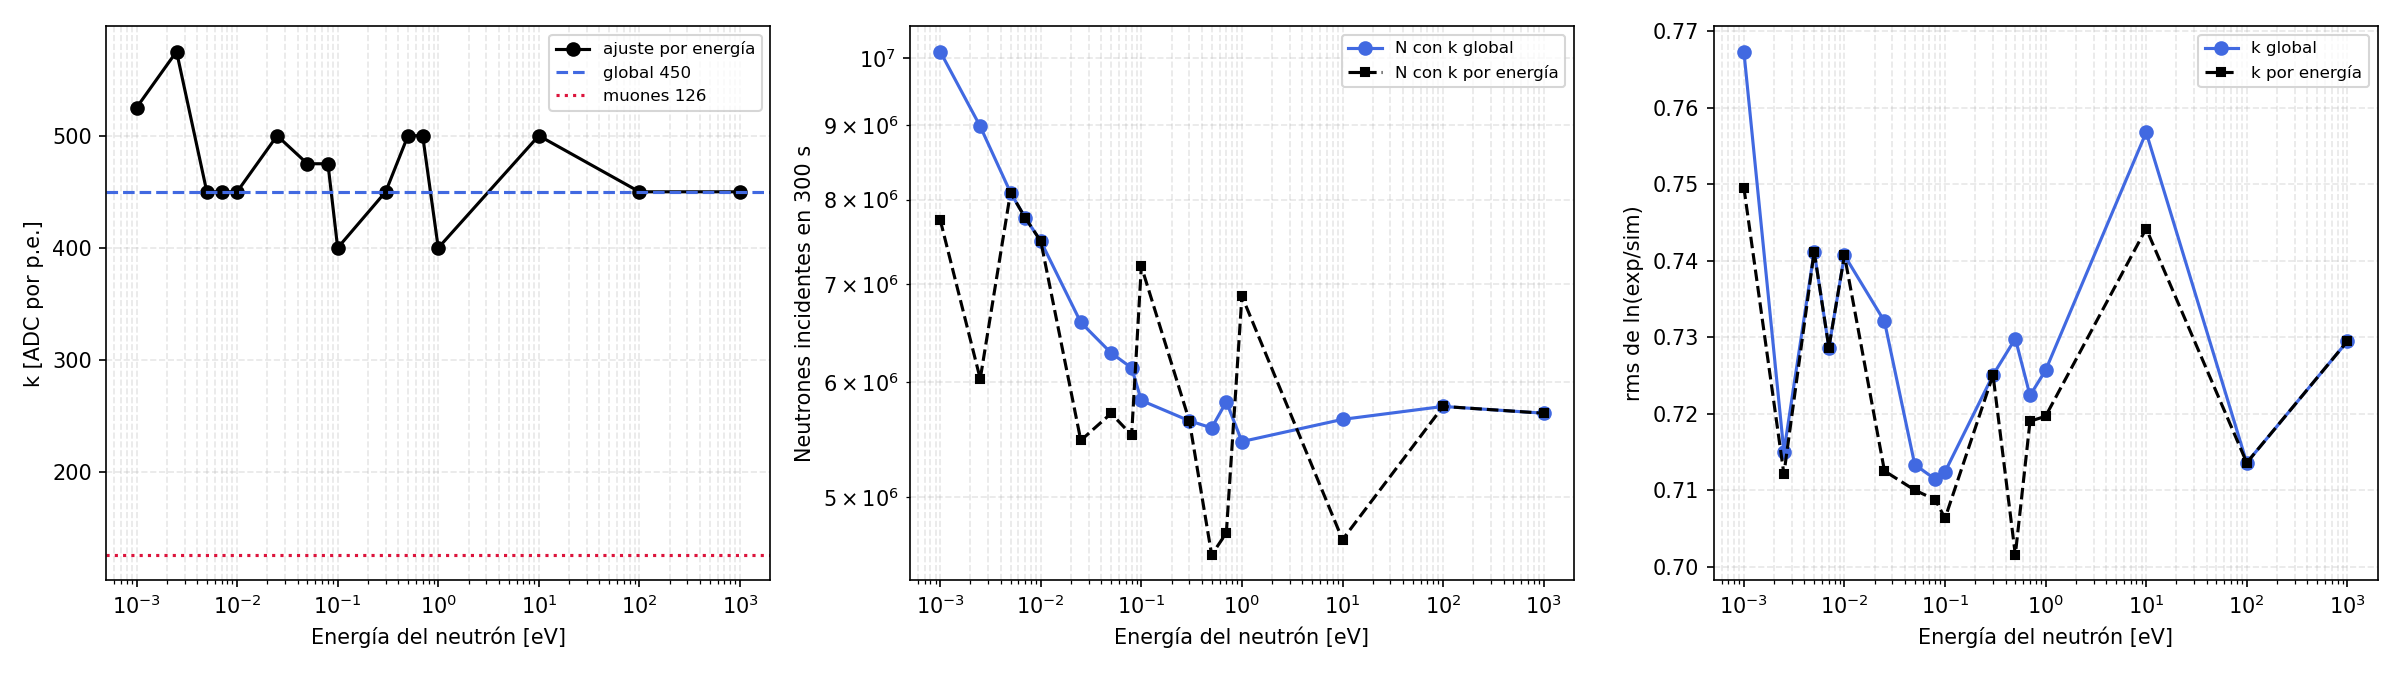

In [11]:
correr("ajuste_factor_comun_campana1.py")
C1 = json.load(open(os.path.join(RES, "ajuste_factor_comun_campana1.json")))
print("k global:", C1["global"]["k_ADC_por_pe"], "ADC/p.e.")
display(pd.DataFrame({e: {"k por energía": v["k_ADC_por_pe"], "N (k por energía)": v["N_inc_300s"], "N (k global)": C1["global"]["N_inc_300s"][e],
                          "rms (k global)": C1["global"]["rms_ln"][e]} for e, v in C1["por_energia"].items()}).T.round(3))
display(Image(os.path.join(FIG, "fig12_campana1_factor_comun.png"), width=1100))
display(Image(os.path.join(FIG, "fig13_campana1_factores.png"), width=1100))

## 6. Tablas del informe

Regenera `informe/tablas/*.tex`. Después de añadir 10 % NaCl, recompilar `informe/Informe-montaje-MEIGA.tex` (dos veces con `pdflatex`).

In [12]:
correr("tablas_informe.py")

tablas en analysis/validacion-experimental-prototipo-AmBe_seccion-4.1.2/Analisis-montaje-MEIGA/informe/tablas ['bandas_carga.tex', 'calibracion_vem.tex', 'exceso_vs_meiga.tex', 'nucleos_modelo5min.tex', 'respuesta_componentes.tex']
 


## Conclusiones

* Entrada lateral: ε(Q ≥ 1) = 17.5 % (agua pura), 22.7 % (2.5 % NaCl) y 29.8 % (10 % NaCl); ⟨Q⟩ = 1.95, 3.93 y 5.30 p.e.; con 10 % el ³⁵Cl recibe el 67.5 % de las capturas.
* Calibración por muones: **≈ 7.9 p.e./kADC**, el doble de 3.95; el disparo (~3000 ADC) equivale a ≈ 24 p.e.
* Las tomas son coherentes (los muones se restan a cero), pero el exceso con fuente (0.08–0.7 VEM) es 10³–10⁴ veces lo que predice MEIGA para 1 Ci (20 000–50 000 pura, 2 000–4 000 con 2.5 %, 4 000–5 000 con 10 %), y su forma casi no cambia con la sal (en MEIGA se alarga ×4.3).
* Con factores comunes (método de los cuadernos) el montaje reproduce los tres medios dentro de un factor 2 con 950 ADC/p.e. y 6×10⁶ neutrones en 300 s, sin desplazar el agua pura; ese factor es ~7 veces el de los muones. La figura de los cuadernos usaba una simulación de neutrones térmicos, no la del montaje.
* El gamma de 4.44 MeV no basta (≈ 5 p.e.). Hipótesis: no linealidad o saturación del PMT, apilamiento a alta tasa, interacción directa en el PMT.